<a href="https://colab.research.google.com/github/lailasadak/lailasadak.github.io/blob/main/October14th.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

from google.colab import files
uploaded = files.upload()


Saving gtex_integrin_7_organs.xlsx to gtex_integrin_7_organs.xlsx


In [ ]:

filename = list(uploaded.keys())[0]

integrins = pd.read_excel(filename)

integrins


,Unnamed: 0,primary_site,ITGA10,ITGAD,ITGAM,ITGA3,ITGBL1,ITGAE,ITGA2,ITGB3,...,ITGA6,ITGA2B,ITGB1,ITGAL,ITGA9,ITGB5,ITGA8,ITGA4,ITGA1,ITGA11
0,GTEX-13QIC-0011-R1a-SM-5O9CJ,Brain,0.5763,-6.5064,2.2573,0.7832,1.0363,4.6035,2.5731,-2.8262,...,2.8562,1.3846,5.8430,1.1316,-0.7108,3.5387,-0.0725,-0.4521,0.2029,-2.8262
1,GTEX-1399S-1726-SM-5L3DI,Lung,4.9137,-3.6259,4.7307,7.1584,1.7702,4.9556,1.9149,2.6067,...,4.2412,4.1211,7.7256,4.4900,2.9281,6.1483,5.1867,2.6185,4.7856,-0.0277
2,GTEX-PWCY-1326-SM-48TCU,Ovary,2.3953,-5.0116,1.4547,4.2593,-0.7346,4.4149,0.2642,1.5216,...,3.6816,1.5465,7.2964,-0.9406,2.7742,5.0414,2.0325,0.7579,2.2573,1.2516
3,GTEX-QXCU-0626-SM-2TC69,Lung,4.0541,-2.3147,4.5053,7.5651,4.1788,4.1772,5.3695,1.8444,...,4.9631,1.9149,7.9947,3.3911,2.8462,6.7683,4.1636,2.7951,5.3284,1.2147
4,GTEX-ZA64-1526-SM-5CVMD,Breast,2.0569,-2.4659,3.3993,3.1311,3.0074,4.4977,-1.7809,2.7139,...,4.7340,0.6332,7.3496,-0.9406,2.5338,6.5696,1.7229,-0.6416,3.1195,1.1050
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1982,GTEX-QMRM-0826-SM-3NB33,Lung,5.3067,-3.8160,4.9065,7.5810,5.8714,4.7345,2.6185,3.1095,...,5.6080,3.7324,8.2849,4.6201,3.6440,6.7052,5.1094,3.3364,5.8153,1.6604
1983,GTEX-YFCO-1626-SM-4W1Z3,Prostate,2.9581,-4.6082,1.1641,4.6938,1.5902,5.8625,-0.5125,1.7617,...,3.8798,-1.4699,7.5163,-0.3752,2.9562,5.3035,4.4304,-0.9406,3.6136,0.4233
1984,GTEX-1117F-2826-SM-5GZXL,Breast,4.3184,-6.5064,1.0433,4.8440,3.5498,4.6809,1.0293,3.3478,...,5.3256,-0.0725,7.7516,1.1382,2.1411,7.1132,0.3796,0.0854,3.8650,1.0151
1985,GTEX-Q2AG-2826-SM-2HMJQ,Brain,3.4622,-5.5735,1.5013,5.4835,1.7702,4.7517,0.6790,-3.1714,...,1.1960,4.1740,4.3002,0.5470,-0.9971,3.7982,-0.2498,1.4808,-0.5125,-0.5125


In [ ]:

ovary_breast = integrins[
    integrins['primary_site'].isin(['Ovary', 'Breast'])
]

# Rearrange data into vertical format
ovary_breast_vertical = ovary_breast.melt(
    id_vars='primary_site',
    var_name='integrin_gene',
    value_name='expression_levels'
)

ovary_breast_vertical


,primary_site,integrin_gene,expression_levels
0,Ovary,Unnamed: 0,GTEX-PWCY-1326-SM-48TCU
1,Breast,Unnamed: 0,GTEX-ZA64-1526-SM-5CVMD
2,Ovary,Unnamed: 0,GTEX-14AS3-1326-SM-5RQJE
3,Breast,Unnamed: 0,GTEX-X4EP-2926-SM-3P5YQ
4,Ovary,Unnamed: 0,GTEX-13N11-0526-SM-5IJFI
...,...,...,...
7471,Ovary,ITGA11,2.694
7472,Breast,ITGA11,-0.0425
7473,Breast,ITGA11,1.5563
7474,Breast,ITGA11,2.3926


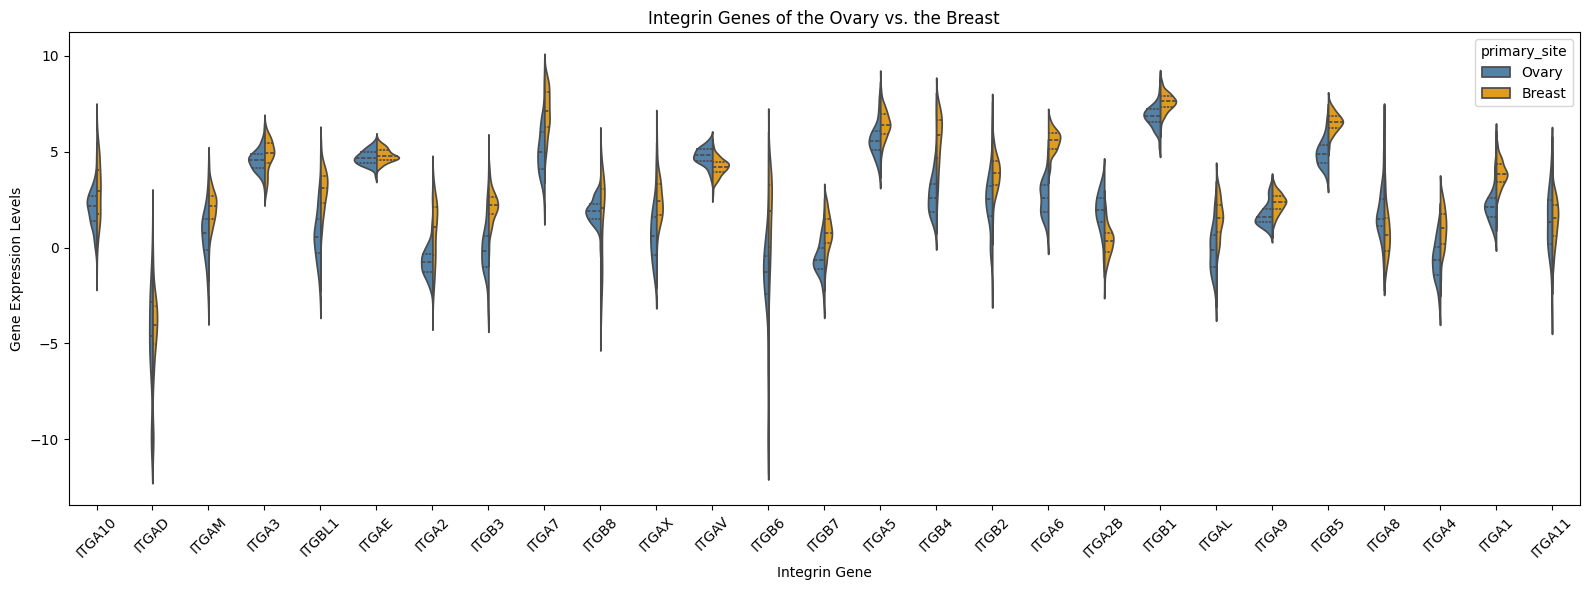

In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

# Make sure expression levels are numeric
ovary_breast_vertical['expression_levels'] = pd.to_numeric(
    ovary_breast_vertical['expression_levels'],
    errors='coerce'
)

# Remove missing values
plot_data = ovary_breast_vertical.dropna(
    subset=['expression_levels']
).copy()

# Create split violin plot
plt.figure(figsize=(16, 6))

sns.violinplot(
    data=plot_data,
    x='integrin_gene',
    y='expression_levels',
    hue='primary_site',
    hue_order=['Ovary', 'Breast'],
    split=True,
    inner='quartile',
    palette={'Ovary': 'steelblue', 'Breast': 'orange'}
)

plt.title("Integrin Genes of the Ovary vs. the Breast")
plt.xlabel("Integrin Gene")
plt.ylabel("Gene Expression Levels")
plt.xticks(rotation=45)
plt.legend(title='primary_site')
plt.tight_layout()
plt.show()


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score

X = ovary_breast[['ITGA1']]
y = ovary_breast['primary_site']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy using ITGA1: {accuracy:.2f}")


Accuracy using ITGA1: 0.94


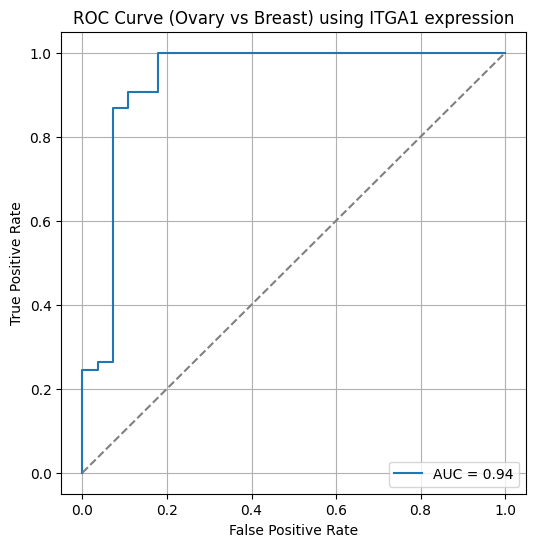

In [ ]:

from sklearn.metrics import roc_curve, roc_auc_score

X = ovary_breast[['ITGA1']]
y = ovary_breast['primary_site'].map({
    'Ovary': 0,
    'Breast': 1
})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

model = LogisticRegression()
model.fit(X_train, y_train)

y_proba = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'AUC = {auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Ovary vs Breast) using ITGA1 expression')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

X = ovary_breast[['ITGA11']]
y = ovary_breast['primary_site']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.4, random_state=42
)

model = LogisticRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)

print(f"Accuracy using ITGA11: {accuracy:.2f}")


Accuracy using ITGA11: 0.67


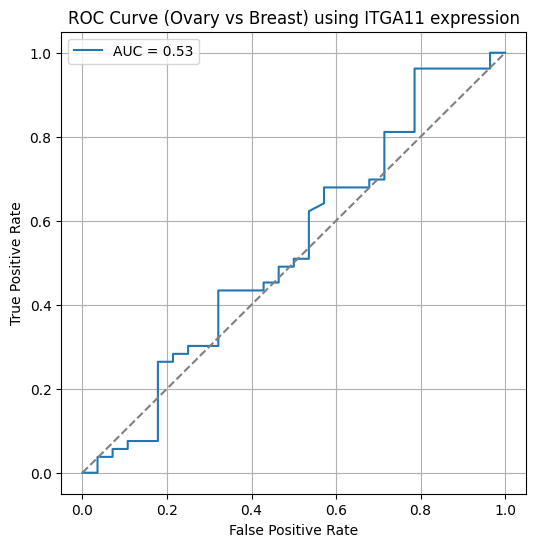

In [ ]:

X = ovary_breast[['ITGA11']]
y = ovary_breast['primary_site'].map({
    'Ovary': 0,
    'Breast': 1
})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42
)

model = LogisticRegression()
model.fit(X_train, y_train)

y_proba = model.predict_proba(X_test)[:, 1]

fpr, tpr, thresholds = roc_curve(y_test, y_proba)
auc = roc_auc_score(y_test, y_proba)

plt.figure(figsize=(6, 6))
plt.plot(fpr, tpr, label=f'AUC = {auc:.2f}')
plt.plot([0, 1], [0, 1], linestyle='--', color='gray')

plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve (Ovary vs Breast) using ITGA11 expression')
plt.legend()
plt.grid(True)
plt.show()


In [ ]:

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

selected_genes = ['ITGA1', 'ITGA11']

X = integrins[selected_genes]
y = integrins['primary_site']

le = LabelEncoder()
y_encoded = le.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42
)

model = LogisticRegression(
    solver='lbfgs',
    max_iter=1000
)

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))

print("\nClassification Report:")
print(classification_report(
    y_test,
    y_pred,
    labels=np.arange(len(le.classes_)),
    target_names=le.classes_,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))


Accuracy: 0.8618090452261307

Classification Report:
              precision    recall  f1-score   support

 Bone Marrow       0.78      0.70      0.74        10
       Brain       0.96      0.98      0.97       247
      Breast       0.65      0.55      0.59        44
       Liver       0.95      0.83      0.88        23
        Lung       0.70      0.93      0.80        43
       Ovary       0.38      0.50      0.43        10
    Prostate       0.58      0.33      0.42        21

    accuracy                           0.86       398
   macro avg       0.72      0.69      0.69       398
weighted avg       0.86      0.86      0.86       398


Confusion Matrix:
[[  7   3   0   0   0   0   0]
 [  2 241   1   0   0   3   0]
 [  0   3  24   0   9   4   4]
 [  0   0   0  19   4   0   0]
 [  0   0   2   1  40   0   0]
 [  0   3   1   0   0   5   1]
 [  0   0   9   0   4   1   7]]


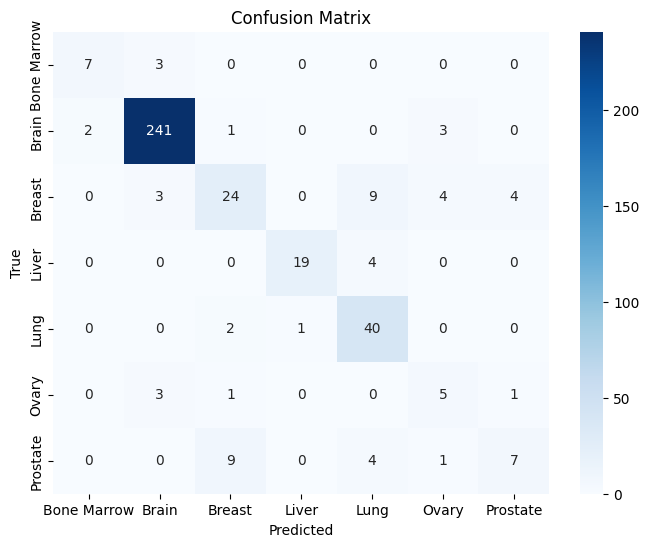

In [ ]:

import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(
    y_test,
    y_pred,
    labels=np.arange(len(le.classes_))
)

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt='d',
    cmap='Blues',
    xticklabels=le.classes_,
    yticklabels=le.classes_
)

plt.xlabel('Predicted')
plt.ylabel('True')
plt.title('Confusion Matrix')
plt.show()
